# Chapitre 1 - Cours 4 : distribué ou mono-nœud

Troisième compromis du chapitre : quand faut-il répartir un système sur plusieurs
machines, et quand vaut-il mieux tout garder sur une seule ? Les systèmes distribués
apportent la tolérance aux pannes, l'échelle et la proximité géographique, mais ils ont un
coût : pannes partielles, latence du réseau, difficulté du diagnostic. Ce notebook couvre
la section *Distributed Versus Single-Node Systems* : *Problems with Distributed Systems*,
*Microservices and Serverless* et *Cloud Computing Versus Supercomputing*.

**Plan.**

1. Pourquoi distribuer : neuf raisons, dont la vitesse de la lumière et l'électricité
   verte.
2. Les problèmes du distribué : délais d'attente ambigus, réessais dangereux, coût d'un
   appel réseau, observabilité.
3. Quand un seul nœud suffit : la métrique COST et le coût du transfert des données.
4. Microservices et serverless : découper par équipes, payer à l'exécution.
5. Cloud contre supercalculateur : disponibilité contre points de reprise.

In [1]:
import json
import socket
import threading
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import architecture as ar
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, set_style, subtitle)
from ddia.sim import Network, Node
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)
fmt = lambda v: f"{v:,.0f}".replace(",", " ")

## 1. Pourquoi distribuer ? (section *Distributed Versus Single-Node Systems*)

Un **système distribué** fait collaborer plusieurs machines qui communiquent par le
réseau ; chaque processus participant est un **nœud**. Le livre énumère les raisons d'en
construire un :

| raison | idée | renvoi |
|---|---|---|
| distribution inhérente | plusieurs utilisateurs sur leurs propres appareils doivent communiquer | |
| requêtes entre services cloud | données stockées dans un service, traitées dans un autre | cours 3 |
| tolérance aux pannes | si une machine (ou un centre de données) tombe, une autre prend le relais | chap. 2, 6 |
| scalabilité | données ou calculs trop gros pour une machine | chap. 2 |
| latence | servir chaque utilisateur depuis un serveur proche | ci-dessous |
| élasticité | ajuster les ressources à la demande | cours 3 |
| matériel spécialisé | disques pour le stockage, GPU pour l'apprentissage | cours 3 |
| conformité légale | lois de résidence des données dans certains pays | cours 5 |
| durabilité | calculer quand et où l'électricité est abondante et décarbonée | ci-dessous |

**La latence et la vitesse de la lumière.** Dans la fibre, la lumière parcourt environ
200 000 km/s, et les câbles ne suivent pas la ligne droite (on compte ici 1,5 fois la
distance orthodromique, `ar.fiber_rtt_ms`). Le temps d'aller-retour (RTT) minimal entre
deux villes est donc incompressible, quels que soient les serveurs.

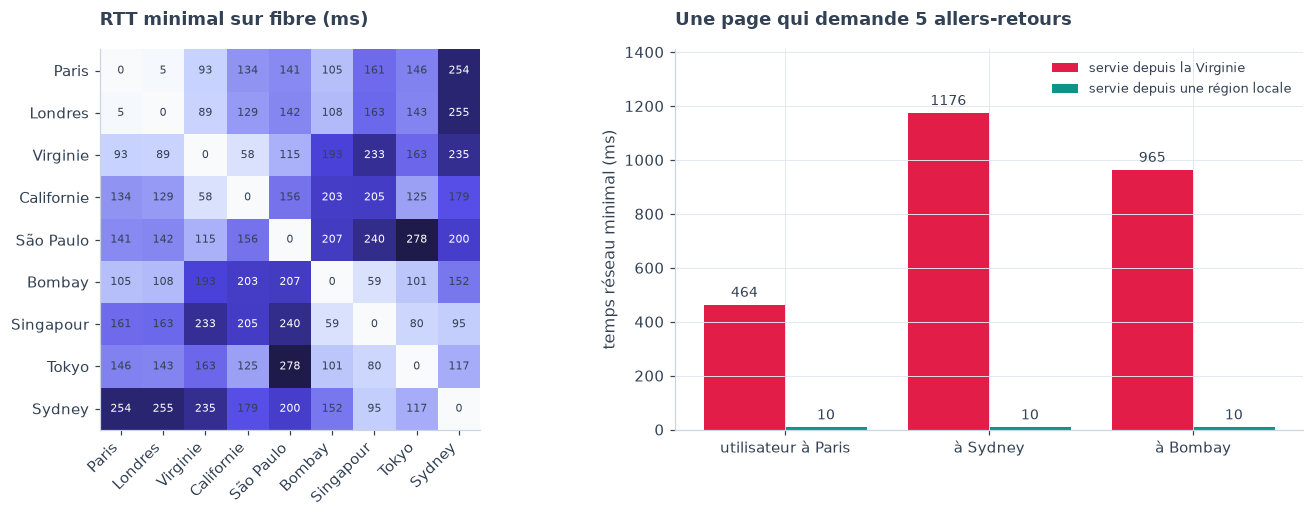

In [2]:
names = ["Paris", "Londres", "Virginie", "Californie", "São Paulo", "Bombay", "Singapour", "Tokyo", "Sydney"]
rtt = np.array([[ar.fiber_rtt_ms(ar.haversine_km(*ar.CITIES[a], *ar.CITIES[b])) for b in names] for a in names])
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.15, 1]})
ax = axes[0]
im = ax.imshow(rtt, cmap="ddia_seq")
ax.set_xticks(range(len(names))); ax.set_xticklabels(names, rotation=45, ha="right")
ax.set_yticks(range(len(names))); ax.set_yticklabels(names); ax.grid(False)
for i in range(len(names)):
    for j in range(len(names)):
        ax.text(j, i, f"{rtt[i, j]:.0f}", ha="center", va="center", fontsize=7.5,
                color="white" if rtt[i, j] > 200 else SLATE)
ax.set_title("RTT minimal sur fibre (ms)")
ax = axes[1]
# une page sécurisée : connexion TCP (1 RTT) + TLS (1 RTT) + requête (1 RTT) + 2 appels API séquentiels
n_rtt = 5
srv = {"servie depuis la Virginie": [rtt[names.index(u), names.index("Virginie")] * n_rtt for u in ["Paris", "Sydney", "Bombay"]],
       "servie depuis la région la plus proche": [rtt[names.index(u), names.index(u)] * n_rtt + 5 * 2 for u in ["Paris", "Sydney", "Bombay"]]}
x = np.arange(3)
b1 = ax.bar(x - 0.2, srv["servie depuis la Virginie"], 0.4, color=ROSE, label="servie depuis la Virginie")
b2 = ax.bar(x + 0.2, srv["servie depuis la région la plus proche"], 0.4, color=TEAL, label="servie depuis une région locale")
annotate_bars(ax, "{:.0f}")
ax.set_xticks(x); ax.set_xticklabels(["utilisateur à Paris", "à Sydney", "à Bombay"])
ax.set_ylabel("temps réseau minimal (ms)"); ax.set_ylim(0, max(srv["servie depuis la Virginie"]) * 1.2)
ax.set_title(f"Une page qui demande {n_rtt} allers-retours"); ax.legend(fontsize=8.5)
plt.tight_layout(); plt.show()

Un utilisateur à Sydney servi depuis la Virginie attend plus d'une seconde de pur trajet
réseau pour une page qui demande cinq allers-retours, avant tout calcul ; servi depuis
une région proche (on compte 2 ms par aller-retour local), une dizaine de millisecondes. Aucune optimisation logicielle ne
compense la physique : seule la **distribution géographique** des serveurs le peut, avec
les problèmes de réplication qu'elle entraîne (chapitre 6).

**La durabilité.** Une tâche différable (un traitement par lots, un entraînement) peut être
déplacée vers les heures et les lieux où l'électricité est abondante et décarbonée.
Exemple synthétique : l'intensité carbone d'un réseau électrique baisse en milieu de
journée grâce au solaire ; une tâche de 4 heures, à finir dans les 24 heures, peut
choisir sa fenêtre.

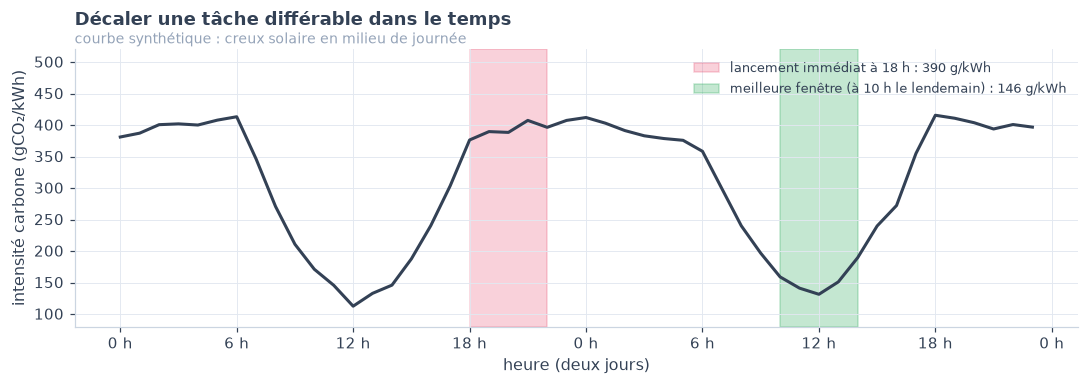

émissions réduites de 63% sans rien changer au calcul


In [3]:
hours = np.arange(48)
solar = np.clip(np.sin((hours % 24 - 6) / 12 * np.pi), 0, None)
carbon = 380 - 230 * solar + 25 * np.sin(hours / 3.0) + rng.normal(0, 8, hours.size)   # gCO2/kWh
job = 4
window = np.array([carbon[s:s + job].mean() for s in range(18, 18 + 24 - job + 1)])
best = 18 + int(window.argmin())
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(hours, carbon, color=SLATE)
ax.axvspan(18, 18 + job, color=ROSE, alpha=0.2, label=f"lancement immédiat à 18 h : {carbon[18:18 + job].mean():.0f} g/kWh")
ax.axvspan(best, best + job, color=GREEN, alpha=0.25, label=f"meilleure fenêtre (à {best % 24} h le lendemain) : {window.min():.0f} g/kWh")
ax.set_xticks(range(0, 49, 6)); ax.set_xticklabels([f"{h % 24} h" for h in range(0, 49, 6)])
ax.set_xlabel("heure (deux jours)"); ax.set_ylabel("intensité carbone (gCO₂/kWh)")
ax.set_title("Décaler une tâche différable dans le temps")
subtitle(ax, "courbe synthétique : creux solaire en milieu de journée")
ax.legend(fontsize=8.5, loc="upper right"); ax.set_ylim(80, 520)
plt.tight_layout(); plt.show()
print(f"émissions réduites de {1 - window.min() / carbon[18:18 + job].mean():.0%} sans rien changer au calcul")

> **À retenir.** On distribue pour des raisons qu'aucune machine unique ne satisfait :
> plusieurs utilisateurs, tolérance aux pannes, échelle, proximité géographique (la
> lumière ne va pas plus vite), élasticité, matériel spécialisé, lois de résidence,
> électricité décarbonée.